# <span style="color:darkblue"> Lecture 11c - Plots  </span>

<font size = "5">

In this lecture we will work on the aesthetics of graphs

- Work with subplots
- Change different aspects of the layout

# <span style="color:darkblue"> I. Setup working environment  </span>

<font size = "5">

Import libraries

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib import ticker
import matplotlib.dates as mdates

<font size = "5">
Import data and parse columns

In [2]:
portfolios = pd.read_csv("data_raw/portfolios.csv")
portfolios["date"] = pd.to_datetime(portfolios["date_str"])

# <span style="color:darkblue"> II. Subplots  </span>

<font size = "5">

Subplot size


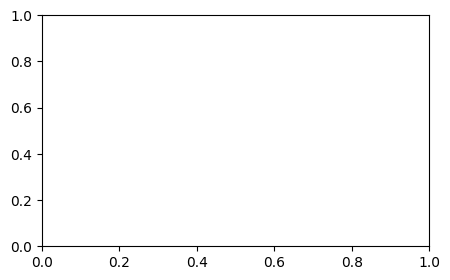

In [3]:

# Create an empty layout with 1 row x 1 column
# "figsize" takes a  list with the width and height

fig, ax = plt.subplots(1,1,figsize = [5,3])

<font size = "5">

Subplots + Lines

Text(0.5, 1.0, 'Portfolio performance over time')

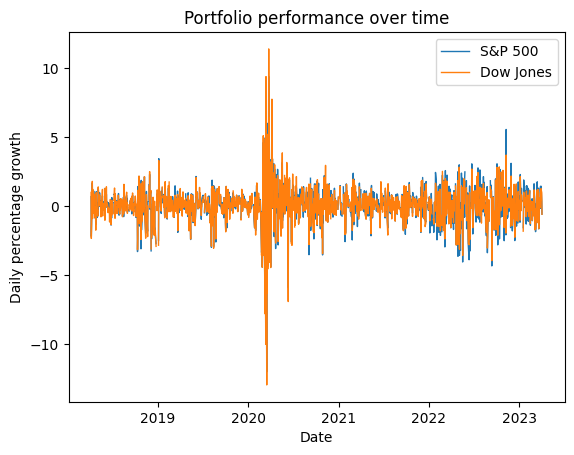

In [4]:
# Extract information that we want to plot
# Indicate that "date" is the x-axis
plot_data = portfolios[["date","growth_sp500","growth_djia"]].set_index("date")

# Generate basic lineplot 
# We add with the subplot environment and add more info
# The linewidth option controls how thin the lines are
# With subplots we use "set_xlabel" rather than "xlabel"
fig, ax = plt.subplots(1,1)
ax.plot(plot_data,
        linewidth=1)
ax.legend(["S&P 500","Dow Jones"])
ax.set_ylabel("Daily percentage growth")
ax.set_xlabel("Date")
ax.set_title("Portfolio performance over time")


In [5]:
portfolios.head(5)

,date_str,sp500,djia,date_ex1,date_ex2,date_ex3,date,diff_sp500,lag_sp500,growth_sp500,diff_date,count_days,diff_djia,lag_djia,growth_djia
0,4/4/2018,2644.69,24264.30,April 04 2018,"Wednesday, 2018-04-04",4-Apr-18,2018-04-04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,4/5/2018,2662.84,24505.22,April 05 2018,"Thursday, 2018-04-05",5-Apr-18,2018-04-05,18.15,2644.69,0.686281,1 days,1.0,240.92,24264.30,0.992899
2,4/6/2018,2604.47,23932.76,April 06 2018,"Friday, 2018-04-06",6-Apr-18,2018-04-06,-58.37,2662.84,-2.192021,1 days,1.0,-572.46,24505.22,-2.336074
3,4/9/2018,2613.16,23979.10,April 09 2018,"Monday, 2018-04-09",9-Apr-18,2018-04-09,8.69,2604.47,0.333657,3 days,3.0,46.34,23932.76,0.193626
4,4/10/2018,2656.87,24408.00,April 10 2018,"Tuesday, 2018-04-10",10-Apr-18,2018-04-10,43.71,2613.16,1.672687,1 days,1.0,428.90,23979.10,1.788641


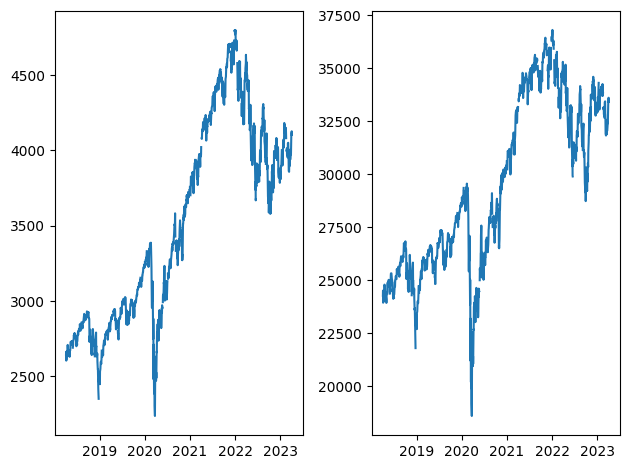

In [6]:
fig, ax = plt.subplots(1,2)

ax[0].plot('date', 'sp500', data = portfolios)
ax[1].plot('date', 'djia', data = portfolios)

fig.tight_layout()

<font size = "5">

Subplots + Histograms

Text(0.5, 1.0, 'Histogram of portfolio growth')

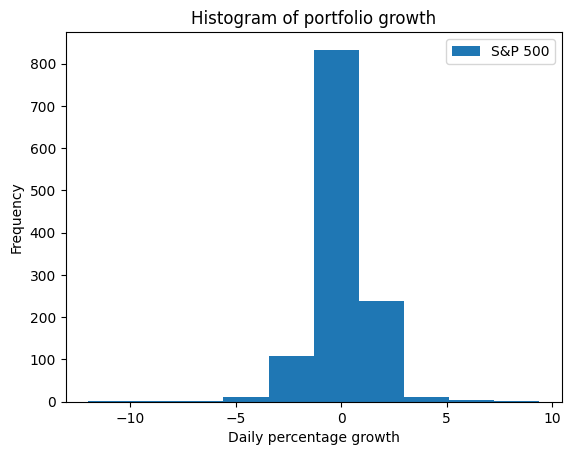

In [7]:
# Baseline plot
fig, ax = plt.subplots(1,1)
ax.hist(x = portfolios["growth_sp500"])
ax.legend(["S&P 500","Dow Jones"])
ax.set_ylabel("Frequency")
ax.set_xlabel("Daily percentage growth")
ax.set_title("Histogram of portfolio growth")


<font size = "5">

Try it yourself!

- Create a scatter plot of "growth_sp500" (y-axis) and <br>
"growth_djia" (x-axis) using ```.subplots()```
- Label the axes and the title.

HINT: Write ``` ax.scatter(x = ..., y = ...) ```


Text(0.5, 1.0, 'Daily growth: S&P 500 vs. Dow Jones')

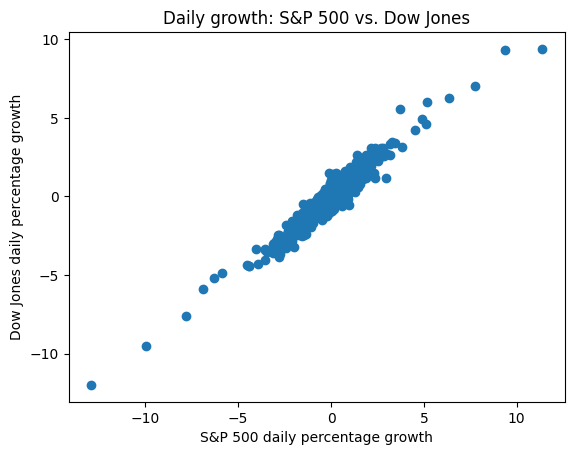

In [15]:
# Write your own code


fig, ax = plt.subplots()

ax.scatter(x=portfolios["growth_djia"], y=portfolios["growth_sp500"])
ax.set_xlabel("S&P 500 daily percentage growth")
ax.set_ylabel("Dow Jones daily percentage growth")
ax.set_title("Daily growth: S&P 500 vs. Dow Jones")





# <span style="color:darkblue"> III. Colors, size, and padding  </span>

<font size = "5">

Formatting axis labels


Text(0.5, 0, 'Date')

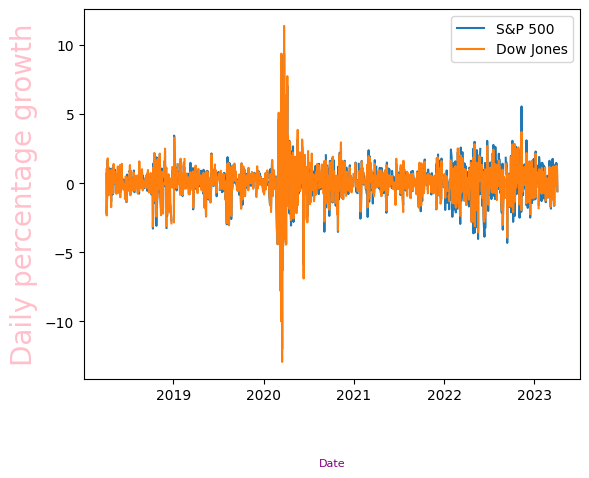

In [9]:
# Baseline plot
fig, ax = plt.subplots(1,1)
ax.plot(portfolios[["date","growth_sp500","growth_djia"]].set_index("date"))
ax.legend(["S&P 500","Dow Jones"])

# labelpad is the space between the labels and the numbers
ax.set_ylabel("Daily percentage growth",
              fontsize = 20,
              color = "pink",
              labelpad = 5)
ax.set_xlabel("Date",
              fontsize = 8,
              color = "purple",
              labelpad = 40)


<font size = "5">

Formatting ticks


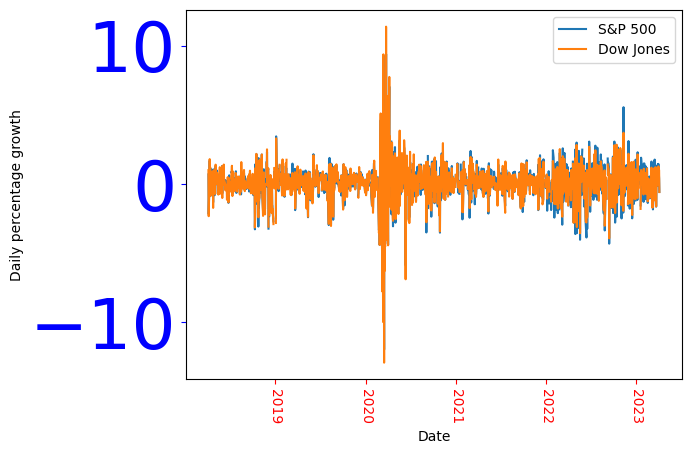

In [10]:
# Baseline plot
fig, ax = plt.subplots(1,1)
ax.plot(portfolios[["date","growth_sp500","growth_djia"]].set_index("date"))
ax.legend(["S&P 500","Dow Jones"])
ax.set_ylabel("Daily percentage growth")
ax.set_xlabel("Date")

# Change format of ticks
# Rotation is an angle from -90 to 90 degrees
ax.xaxis.set_tick_params(labelsize = 10,
                         rotation=-90,
                         colors = "red")
ax.yaxis.set_tick_params(labelsize = 50,
                         rotation=0,
                         colors = "blue")


<font size = "5">

Try it yourself!

- Copy-paste the code for the histogram above
- Change the formatting of the x-axis by <br> <br>
(a) rotating the labels by 45 degrees with <br>
```set_tick_params()```<br> <br>
 (b) increasing the padding with <br>
 ```set_xlabel(...,labelpad = 15)```

Try different values of ```labelpad```

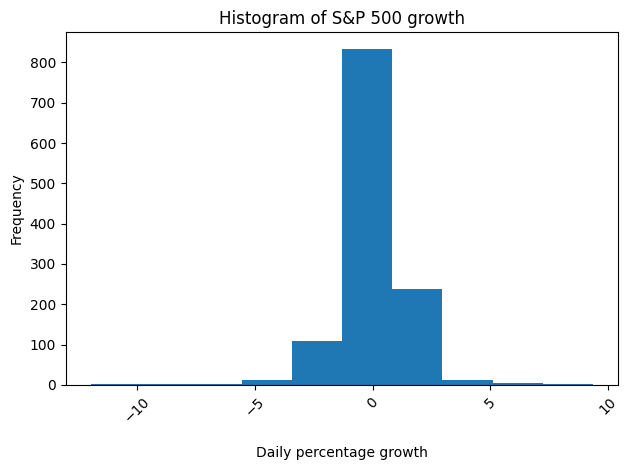

In [16]:
fig, ax = plt.subplots()

ax.hist(portfolios["growth_sp500"])
ax.set_ylabel("Frequency")
ax.set_xlabel("Daily percentage growth", labelpad=15)
ax.set_title("Histogram of S&P 500 growth")
ax.xaxis.set_tick_params(rotation=45)

fig.tight_layout()


# <span style="color:darkblue"> IV. Tick Spacing  </span>

<font size = "5">

Formatting date axes

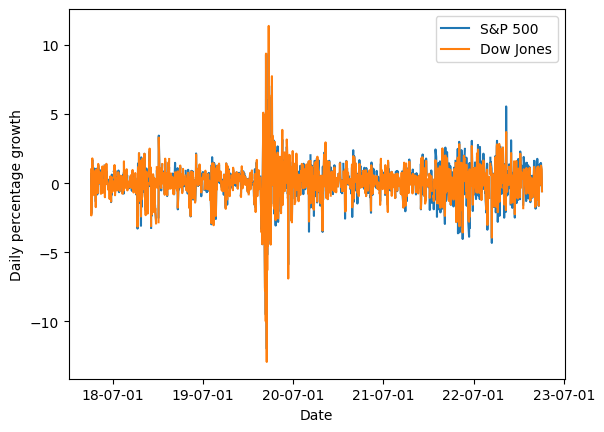

In [12]:
# Baseline plot
fig, ax = plt.subplots(1,1)
ax.plot(portfolios[["date","growth_sp500","growth_djia"]].set_index("date"))
ax.legend(["S&P 500","Dow Jones"])
ax.set_ylabel("Daily percentage growth")
ax.set_xlabel("Date")

# Establish the frequency of labels and their format
# Can also use "DayLocator","MonthLocator", "YearLocator", 
# Use wildcards to set the year format: See lecture on time data

config_ticks = mdates.MonthLocator(interval=12)
format_ticks = mdates.DateFormatter('%y-%m-%d') 

ax.xaxis.set_major_locator(config_ticks)
ax.xaxis.set_major_formatter(format_ticks)


<font size = "5">

Formatting numeric axes

$\qquad$ <img src="figures/wildcard_floats.png" alt="drawing" width="300"/>

(-20.0, 20.0)

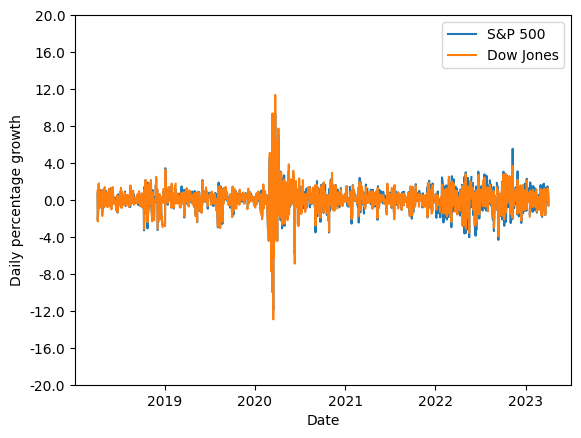

In [13]:
# Baseline plot
fig, ax = plt.subplots(1,1)
ax.plot(portfolios[["date","growth_sp500","growth_djia"]].set_index("date"))
ax.legend(["S&P 500","Dow Jones"])
ax.set_ylabel("Daily percentage growth")
ax.set_xlabel("Date")


# Set number of ticks, configure them, and display them
M = 10
config_ticks = ticker.MaxNLocator(M)
format_ticks = ticker.FormatStrFormatter('%.1f')
ax.yaxis.set_major_locator(config_ticks)
ax.yaxis.set_major_formatter(format_ticks)

# Set graph limits manually
ax.set_ylim(-20,20)


<font size = "5">

Try it yourself!

- Copy-paste the code for the histogram above
- Read the example in "Formatting numeric axes"
- Include 8 ticks on the x-axis, displaying 1 decimal place


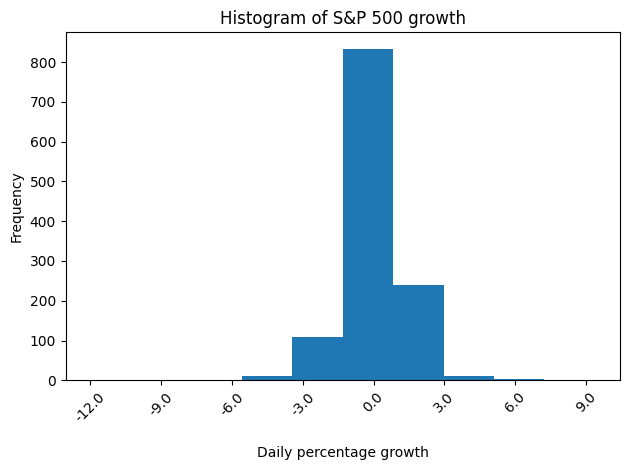

In [18]:
# Copy-paste the histogram code above
fig, ax = plt.subplots()
ax.hist(portfolios["growth_sp500"])
ax.set_ylabel("Frequency")
ax.set_xlabel("Daily percentage growth", labelpad=15)
ax.set_title("Histogram of S&P 500 growth")

# Include 8 ticks on the x-axis and show 1 decimal place
ax.xaxis.set_major_locator(ticker.MaxNLocator(8))
ax.xaxis.set_major_formatter(ticker.FormatStrFormatter('%.1f'))
ax.xaxis.set_tick_params(rotation=45)

fig.tight_layout()


# <span style="color:darkblue"> V. (Optional) More resources  </span>

<font size = "5">

Anatomy of a figure

Soure + more details: https://matplotlib.org/stable/gallery/showcase/anatomy.html


<img src="figures/structure_plot.png" alt="drawing" width="550"/>

<font size = "5">

More on subplot syntax:


https://matplotlib.org/stable/gallery/subplots_axes_and_figures/subplots_demo.html

<font size = "5">

List of colors:

https://matplotlib.org/stable/gallery/color/named_colors.html

<font size = "5">

More options

https://problemsolvingwithpython.com/06-Plotting-with-Matplotlib/06.05-Multi-Line-Plots/